# Dengue Risk Prediction - Sri Lanka
Advanced Machine Learning - Final Assignment
Name: [Your Name] | Student ID: [Student ID]

Goal: predict if a district will be **high risk** for dengue **next week**.
The code is in the `src` folder, this notebook runs it step by step and shows the results.
Training and SHAP/LIME are slow, so by default this notebook reads the saved results.
Change the flags to `True` to run them again.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import pandas as pd
from IPython.display import Image, display

RUN_TRAINING = False   # about 4 minutes
RUN_XAI = False        # about 3 minutes

## 1. Load and check the data

In [2]:
from src.data_prep import prepare_data
from src.config import FEATURES, TARGET
train, test, inference, thresholds, district_list = prepare_data()

Nulls in each column:
start_date    0
year          0
week          0
district      0
cases         0
dtype: int64
Duplicate rows (same district and week): 0
Puttalam is missing 1 week(s)
Weekly cases -> median: 9.0  mean: 31.7  max: 2631.0
Missing weeks found: 1
Train rows: 24336 (2007-2024)
Test rows: 1846 (2025-2026)
Held out week: 2026-05-04 - 26 districts
High risk weeks -> train 24.4%, test 45.7%


In [3]:
train[["start_date", "district"] + FEATURES + ["cases_next_week", "risk_threshold", TARGET]].tail()

,start_date,district,cases_this_week,cases_1_week_ago,cases_2_weeks_ago,cases_3_weeks_ago,average_last_4_weeks,change_from_last_week,week,month,district_code,cases_vs_threshold,avg4_vs_threshold,cases_next_week,risk_threshold,high_risk
26234,2024-11-16,Vavuniya,5.0,0.0,2.0,1.0,2.00,5.0,48,11,25,0.000000,-0.693147,3.0,5.0,0
26235,2024-11-23,Vavuniya,3.0,5.0,0.0,2.0,2.50,-2.0,49,11,25,-0.405465,-0.538997,2.0,5.0,0
26236,2024-11-30,Vavuniya,2.0,3.0,5.0,0.0,2.50,-1.0,50,11,25,-0.693147,-0.538997,4.0,5.0,0
26237,2024-12-07,Vavuniya,4.0,2.0,3.0,5.0,3.50,2.0,51,12,25,-0.182322,-0.287682,4.0,5.0,0
26238,2024-12-14,Vavuniya,4.0,4.0,2.0,3.0,3.25,0.0,52,12,25,-0.182322,-0.344840,2.0,5.0,0


## 2. EDA

Rows: 26311 | Districts: 26
From 2006-12-23 to 2026-05-11
Total cases: 833584
Biggest week: 2017-07-15 with 10590 cases (2017 epidemic)


Colombo threshold: 224.5 | Mannar threshold: 3.0
Western Province share of all cases: 41%


Skewness: raw 10.2, after log 0.20


Autocorrelation lag 1: 0.79, lag 4: 0.70
High risk weeks in Train 2007-2023: 23.6%
High risk weeks in Validation 2024: 36.7%
High risk weeks in Test 2025-2026: 45.7%


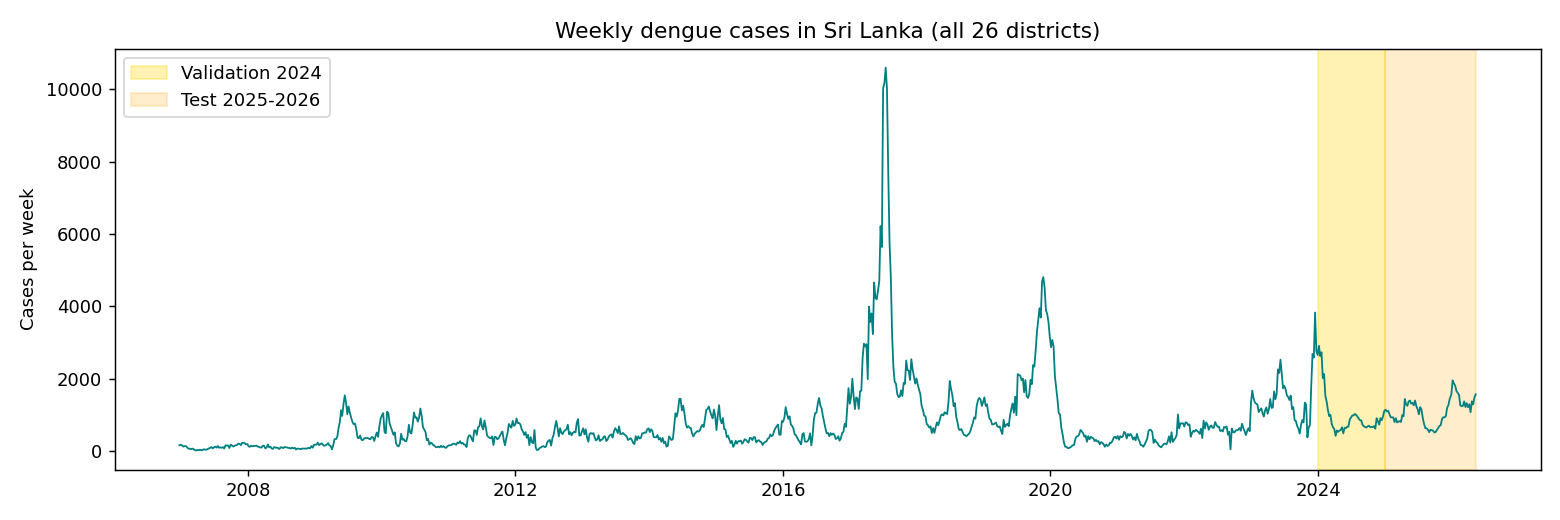

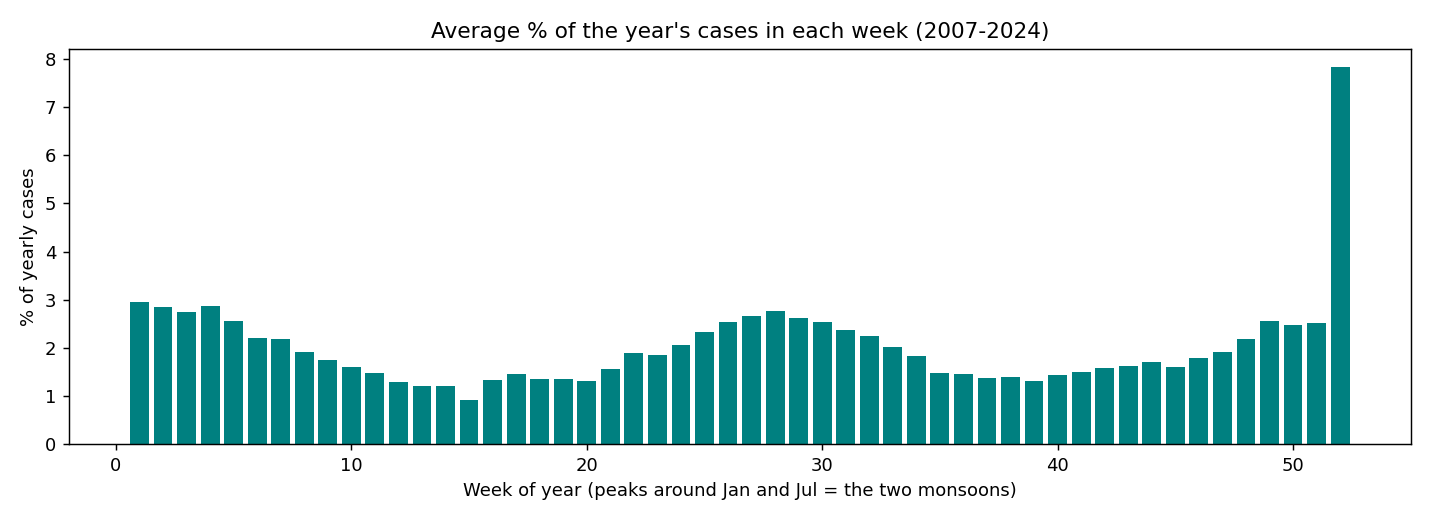

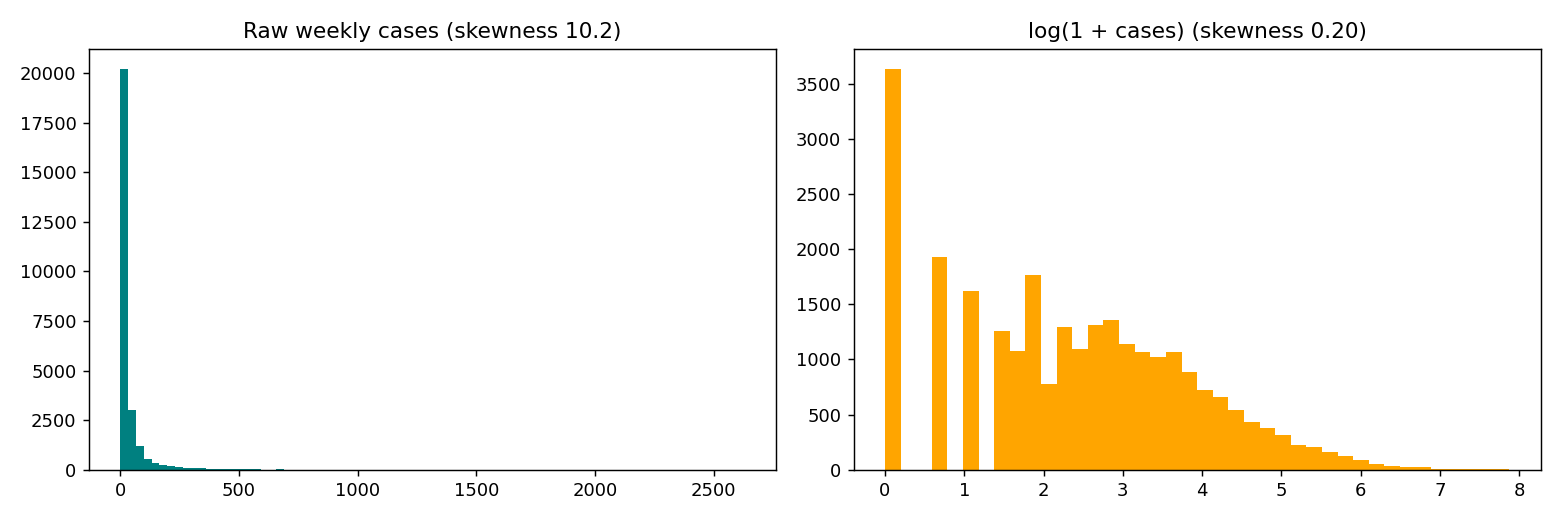

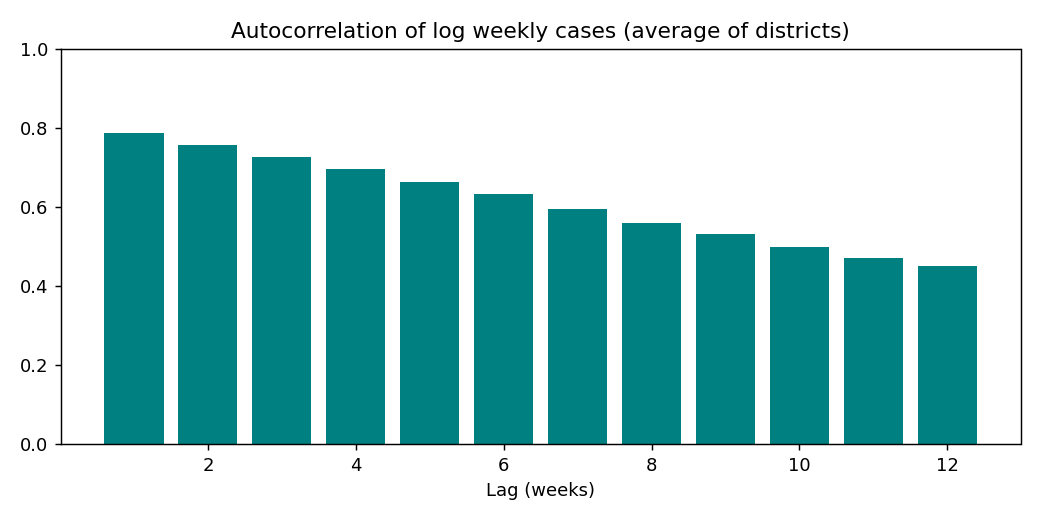

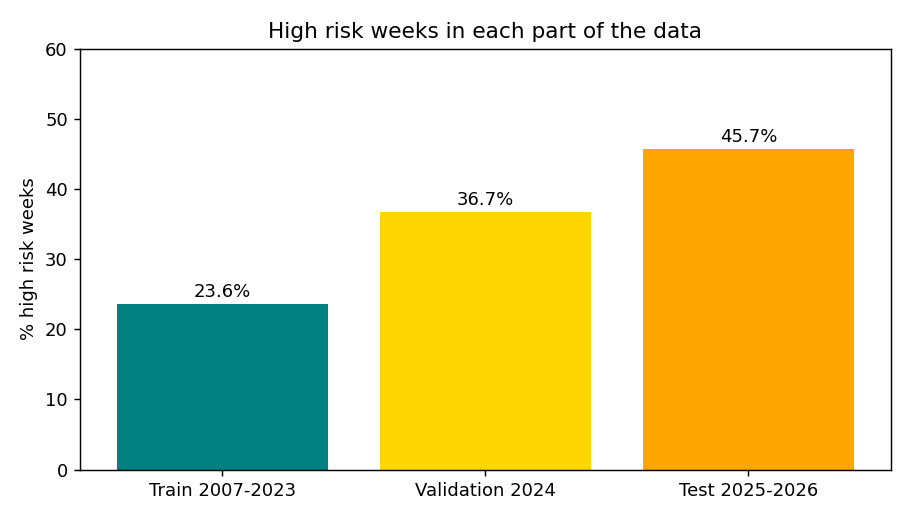

In [4]:
from src import eda
eda.main()
for name in ["eda_national_trend", "eda_seasonality", "eda_distribution", "eda_autocorrelation", "eda_class_balance"]:
    display(Image(f"reports/figures/{name}.png", width=800))

What I take from this:
- very skewed -> log transform
- peaks in Jan and Jul -> week and month as features
- strong link between weeks -> lag features + a simple "persistence rule" to compare with
- Colombo is much bigger than Mannar -> a threshold for each district
- 2025-26 has many more high-risk weeks -> class weights and PR-AUC

## 3. Preprocessing + model pipeline

In [5]:
from src.models import create_model
create_model("Logistic Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('counts', ...), ('others', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transf

## 4. Hyperparameter tuning results

In [6]:
tuning = pd.read_csv("reports/tuning_results.csv")
tuning.groupby("model", sort=False).head(3)

,model,params,mean_test_f1,std_test_f1,mean_test_pr_auc,rank_test_f1
0,Random Forest,"{'model__class_weight': 'balanced', 'model__ma...",0.693641,0.134614,0.762895,1
1,Random Forest,"{'model__class_weight': 'balanced', 'model__ma...",0.692805,0.133165,0.762286,2
2,Random Forest,"{'model__class_weight': 'balanced', 'model__ma...",0.692037,0.137011,0.751236,3
16,XGBoost,"{'model__learning_rate': 0.05, 'model__max_dep...",0.694114,0.144030,0.756421,1
17,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.687859,0.143750,0.744224,2
18,XGBoost,"{'model__learning_rate': 0.05, 'model__max_dep...",0.687360,0.145105,0.746789,3
28,LightGBM,"{'model__learning_rate': 0.05, 'model__num_lea...",0.693310,0.141137,0.757398,1
29,LightGBM,"{'model__learning_rate': 0.05, 'model__num_lea...",0.686992,0.144335,0.746611,2
30,LightGBM,"{'model__learning_rate': 0.1, 'model__num_leav...",0.682436,0.149059,0.743892,3
40,CatBoost,"{'model__auto_class_weights': 'SqrtBalanced', ...",0.695949,0.137187,0.752001,1


## 5. Train and compare the 9 models

In [7]:
from src import train as train_step, charts
if RUN_TRAINING:
    train_step.main()
    charts.main()
print("Validation 2024 (used to choose):")
display(pd.read_csv("reports/validation_metrics.csv", index_col="Model"))
print("Test 2025-2026:")
display(pd.read_csv("reports/metrics.csv", index_col="Model"))
info = json.load(open("models/model_info.json"))
print("Best model:", info["best_model"])

Validation 2024 (used to choose):


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training time (s)
Model,,,,,,,
Persistence rule,0.7966,0.7097,0.7540,0.7312,0.8671,0.8094,0.0
Logistic Regression,0.7419,0.5951,0.9274,0.7250,0.8920,0.8381,0.2
Decision Tree,0.7337,0.5899,0.8992,0.7125,0.8856,0.8270,0.1
Random Forest,0.7825,0.6512,0.8770,0.7474,0.8941,0.8476,7.4
XGBoost,0.7537,0.6118,0.8992,0.7282,0.8931,0.8443,1.1
LightGBM,0.7537,0.6115,0.9012,0.7286,0.8940,0.8452,0.6
CatBoost,0.7966,0.6889,0.8125,0.7456,0.8940,0.8456,2.2
Soft Voting,0.7751,0.6399,0.8851,0.7428,0.8952,0.8479,13.3
Stacking,0.7552,0.6129,0.9032,0.7302,0.8956,0.8493,51.7


Test 2025-2026:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training time (s)
Model,,,,,,,
Persistence rule,0.7709,0.7512,0.7450,0.7481,0.8337,0.7911,0.0
Logistic Regression,0.7449,0.6587,0.9158,0.7663,0.8561,0.7903,0.1
Decision Tree,0.7394,0.6534,0.9146,0.7622,0.8586,0.8190,0.1
Random Forest,0.7730,0.7031,0.8707,0.7780,0.8773,0.8590,7.6
XGBoost,0.7573,0.6781,0.8921,0.7705,0.8710,0.8466,0.5
LightGBM,0.7481,0.6684,0.8897,0.7634,0.8683,0.8412,0.6
CatBoost,0.7736,0.7239,0.8149,0.7667,0.8702,0.8441,2.5
Soft Voting,0.7589,0.6888,0.8612,0.7654,0.8736,0.8532,11.6
Stacking,0.7584,0.6771,0.9004,0.7729,0.8763,0.8581,56.4


Best model: Stacking


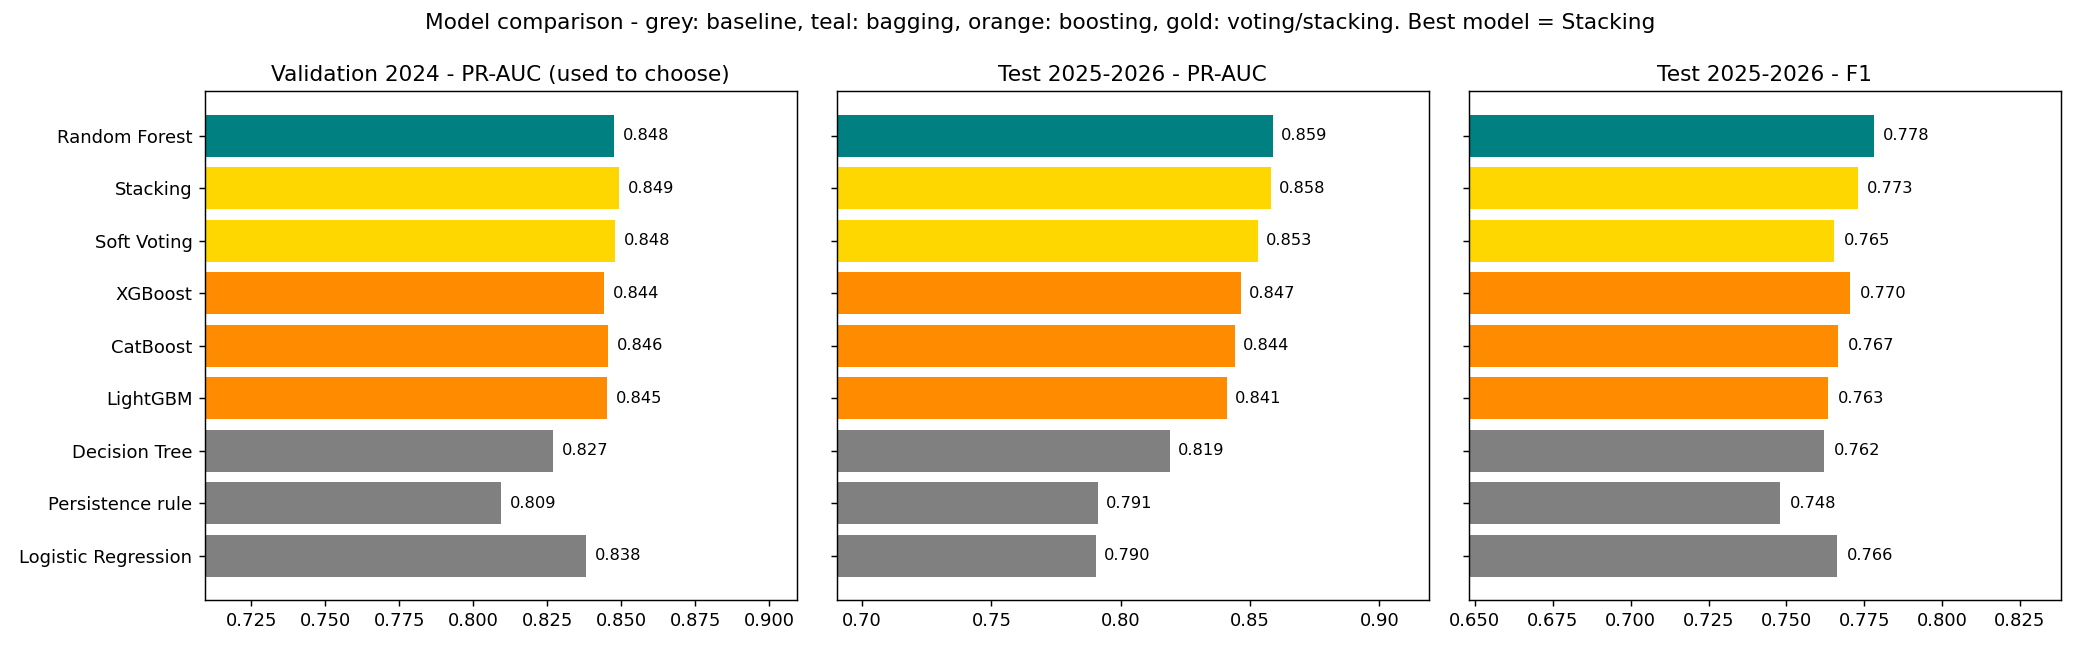

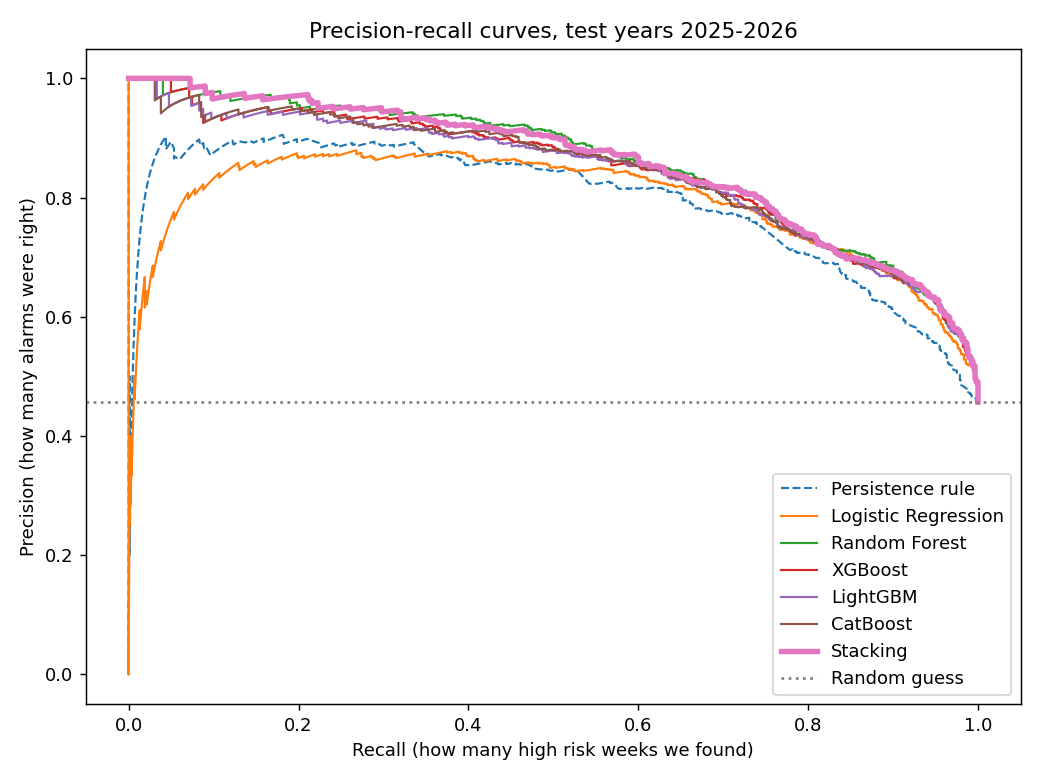

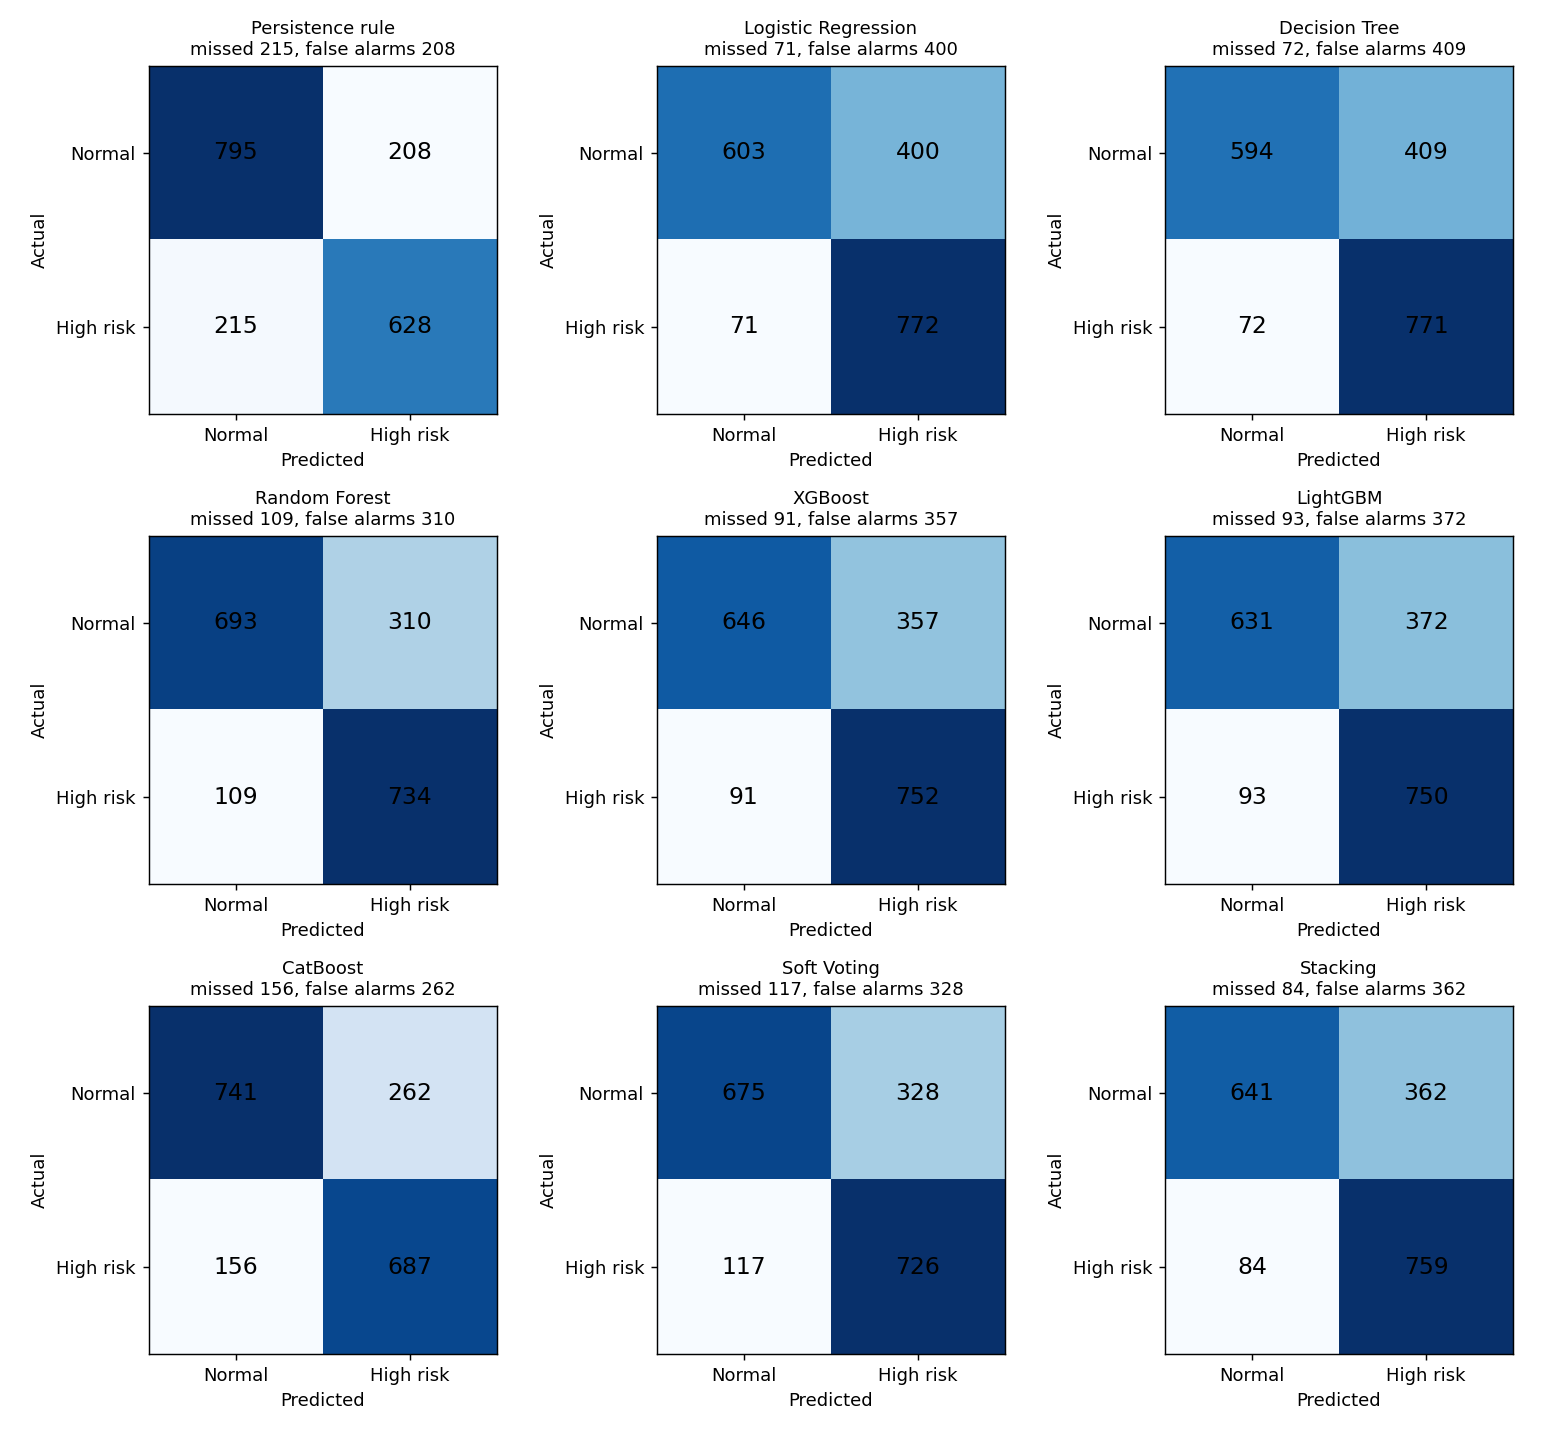

,Model,Setting,Recall,F1,PR-AUC
0,Random Forest,Default parameters,0.700,0.748,0.849
1,Random Forest,My parameters,0.871,0.778,0.859
2,XGBoost,Default parameters,0.698,0.740,0.827
3,XGBoost,My parameters,0.892,0.770,0.847
4,LightGBM,Default parameters,0.703,0.752,0.840
5,LightGBM,My parameters,0.890,0.763,0.841
6,CatBoost,Default parameters,0.707,0.751,0.842
7,CatBoost,My parameters,0.815,0.767,0.844


In [8]:
for name in ["model_comparison", "pr_curves", "confusion_matrices"]:
    display(Image(f"reports/figures/{name}.png", width=900))
pd.read_csv("reports/default_vs_tuned.csv")

- Stacking was best on 2024, so I chose it. On the test years: PR-AUC 0.858, recall 0.90.
- It finds 131 more high-risk weeks than the simple rule (misses 84 instead of 215).
- My parameters are better than the defaults, mostly because of the class weights.

In [9]:
pd.read_csv("reports/feature_test.csv")

,experiment,model,setting,PR-AUC,F1
0,A features,Logistic Regression,without threshold features,0.840,0.723
1,A features,Logistic Regression,with threshold features,0.838,0.725
2,A features,Random Forest,without threshold features,0.776,0.704
3,A features,Random Forest,with threshold features,0.848,0.747
4,A features,XGBoost,without threshold features,0.822,0.720
5,A features,XGBoost,with threshold features,0.844,0.728
6,A features,LightGBM,without threshold features,0.835,0.736
7,A features,LightGBM,with threshold features,0.845,0.729
8,A features,CatBoost,without threshold features,0.828,0.732
9,A features,CatBoost,with threshold features,0.846,0.746


## 6. SHAP and LIME

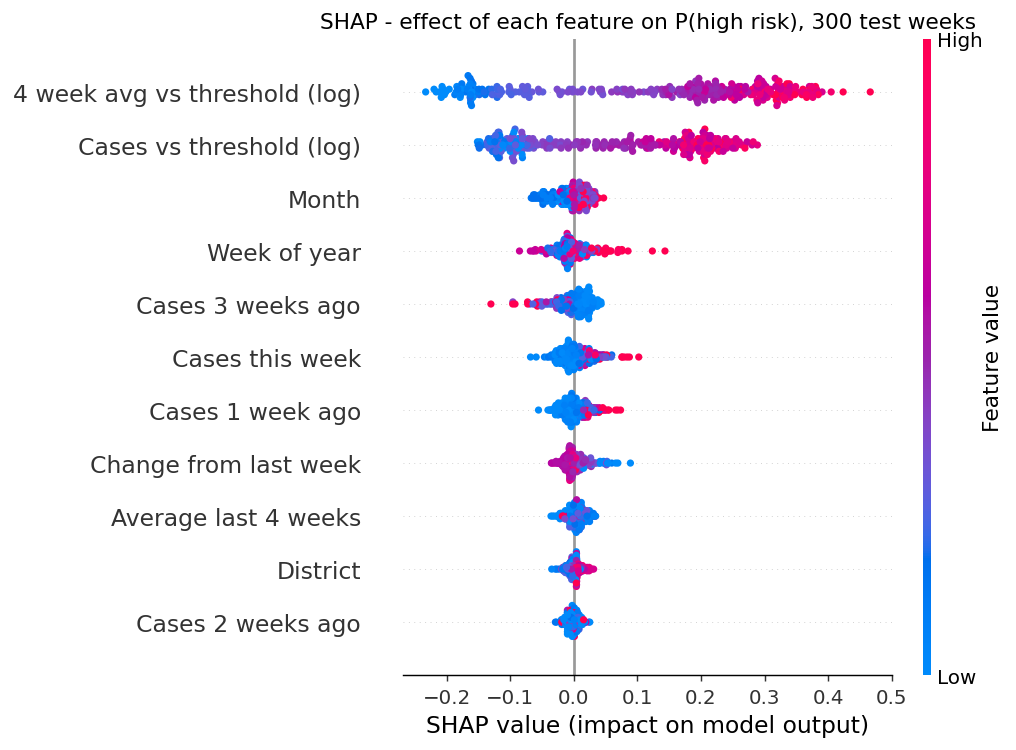

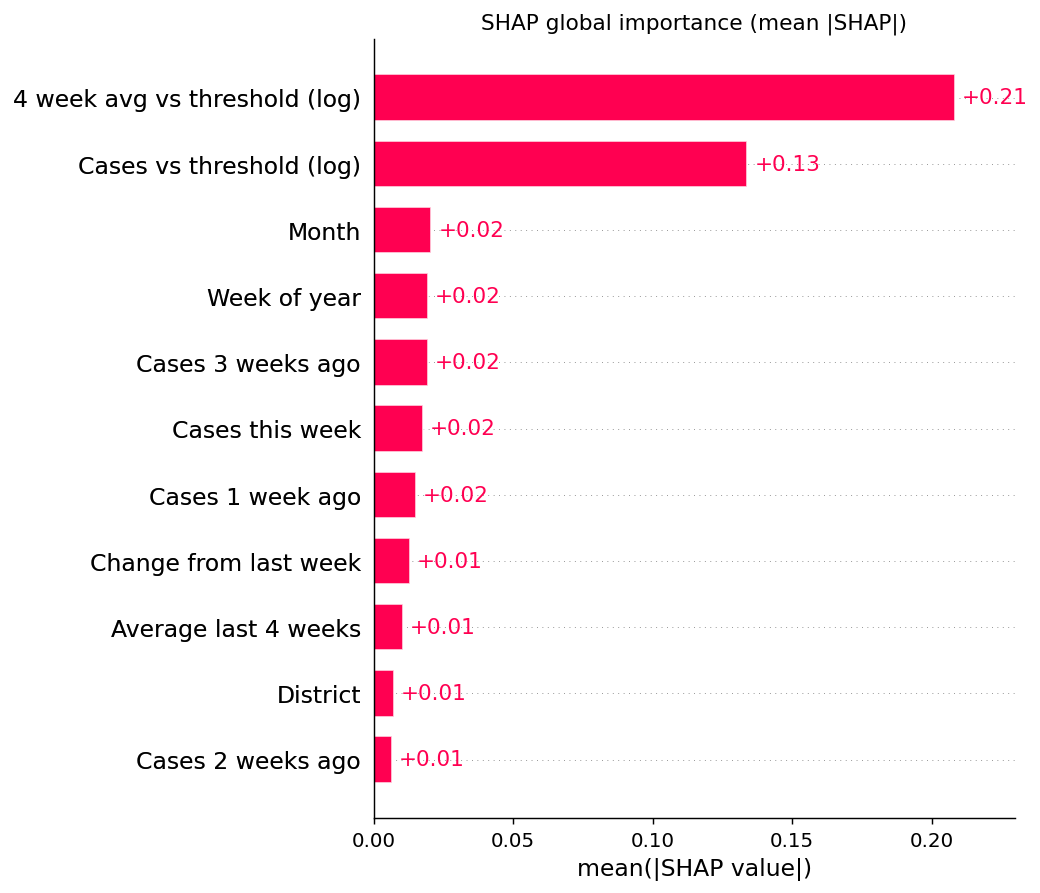

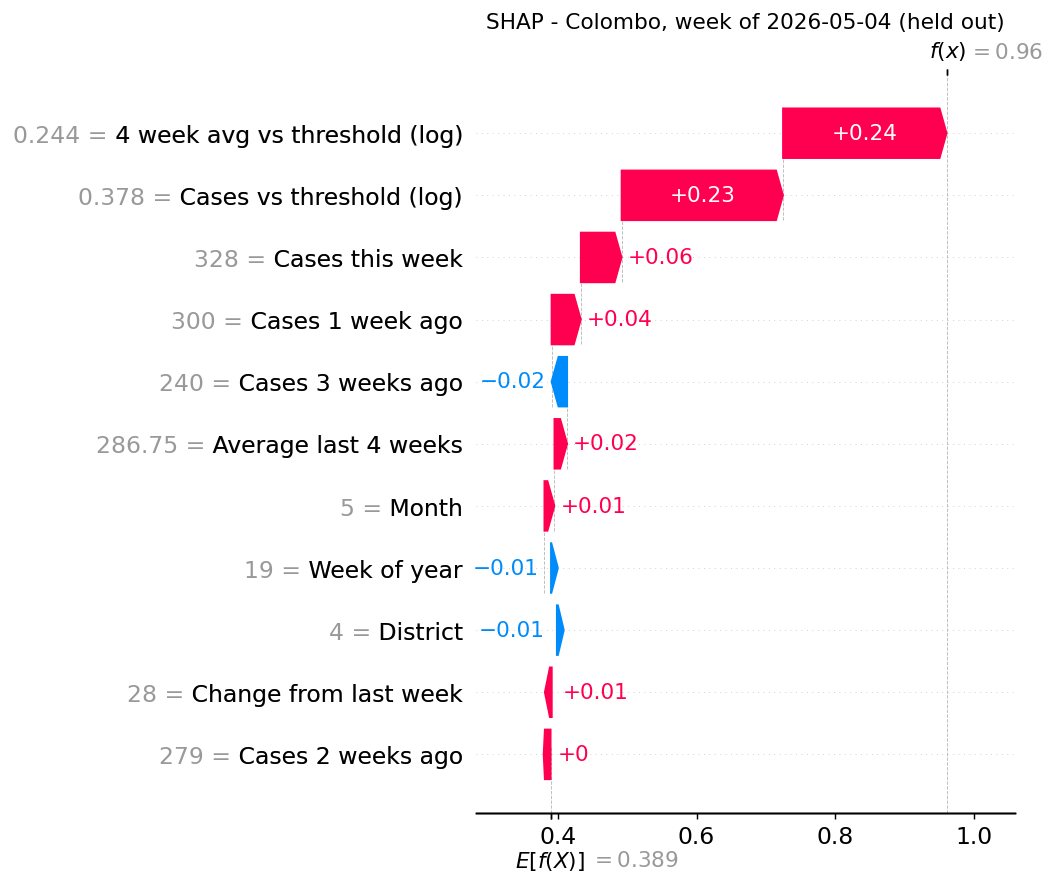

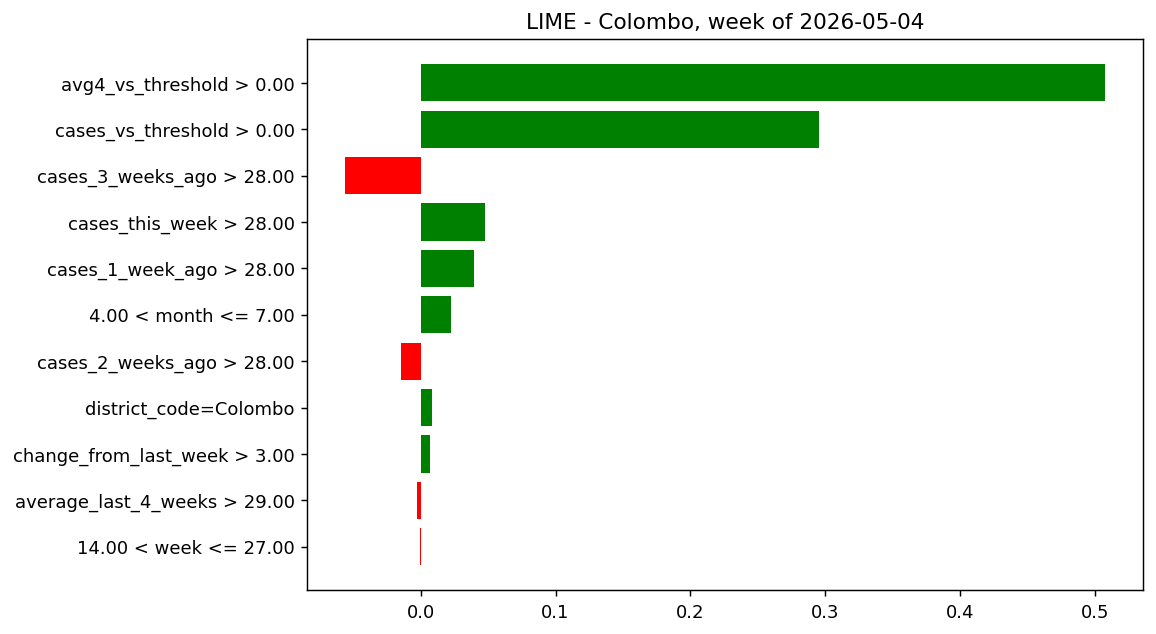

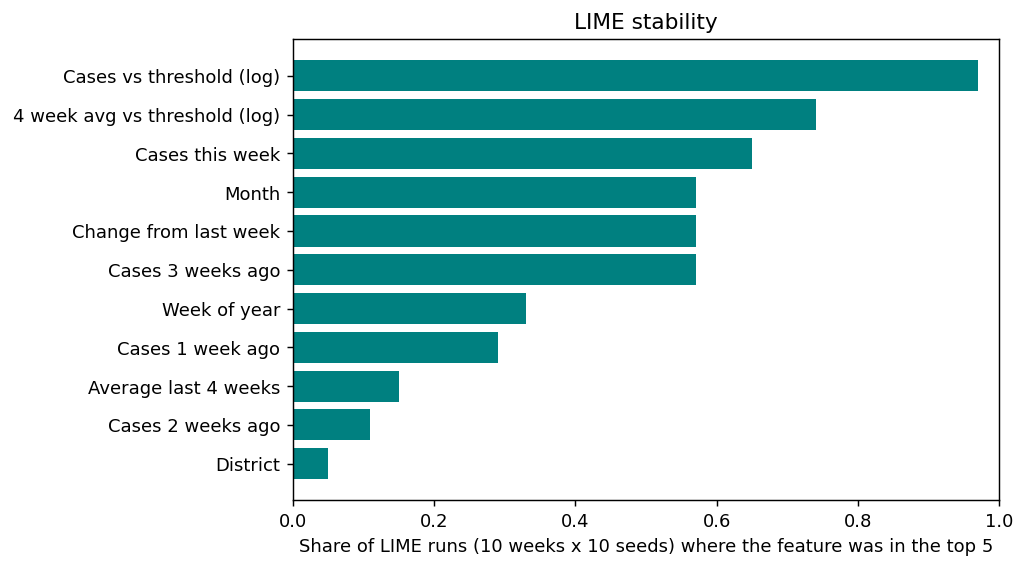

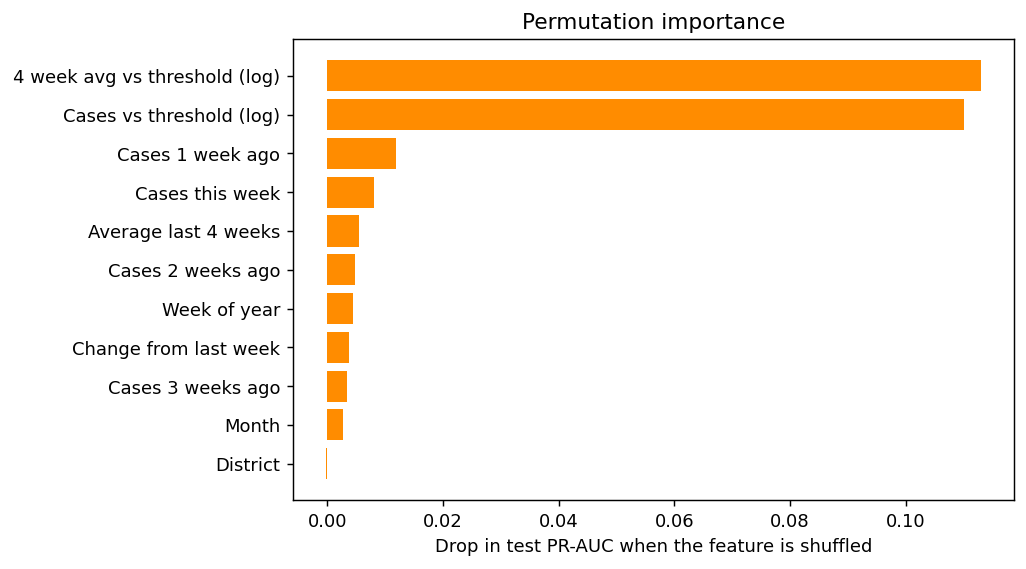

In [10]:
from src import explain
if RUN_XAI:
    explain.main()
for name in ["xai_shap_beeswarm", "xai_shap_bar", "xai_shap_waterfall_colombo", "xai_lime_colombo",
             "xai_lime_stability", "xai_permutation_importance"]:
    display(Image(f"reports/figures/{name}.png", width=750))

In [11]:
display(pd.read_csv("reports/xai/shap_colombo.csv"))
display(pd.read_csv("reports/xai/lime_colombo.csv"))
display(pd.read_csv("reports/xai/lime_vs_shap_cases.csv"))
json.load(open("reports/xai/xai_summary.json"))

,feature,value,shap
0,4 week avg vs threshold (log),0.24,0.2359
1,Cases vs threshold (log),0.38,0.2328
2,Cases this week,328.0,0.0588
3,Cases 1 week ago,300.0,0.0422
4,Cases 3 weeks ago,240.0,-0.0225
5,Average last 4 weeks,286.75,0.0184
6,Month,5.0,0.0144
7,Week of year,19.0,-0.0095
8,District,Colombo,-0.0084
9,Change from last week,28.0,0.0073


,condition,weight
0,avg4_vs_threshold > 0.00,0.507621
1,cases_vs_threshold > 0.00,0.295036
2,cases_3_weeks_ago > 28.00,-0.055786
3,cases_this_week > 28.00,0.047447
4,cases_1_week_ago > 28.00,0.039415
5,4.00 < month <= 7.00,0.022567
6,cases_2_weeks_ago > 28.00,-0.014495
7,district_code=Colombo,0.008317
8,change_from_last_week > 3.00,0.006877
9,average_last_4_weeks > 29.00,-0.002951


,district,week,actual,probability,result,lime_stability_jaccard,shap_top3,lime_top3,same_features_in_top3
0,Kandy,2025-09-20,0,0.291,correct,0.636,"cases_vs_threshold, avg4_vs_threshold, cases_3...","cases_1_week_ago, cases_this_week, cases_3_wee...",1
1,Kalutara,2026-02-09,1,0.937,correct,0.770,"avg4_vs_threshold, cases_vs_threshold, month","avg4_vs_threshold, cases_vs_threshold, cases_t...",2
2,Badulla,2025-04-12,0,0.184,correct,0.515,"cases_vs_threshold, avg4_vs_threshold, distric...","cases_vs_threshold, month, avg4_vs_threshold",2
3,Jaffna,2025-07-26,0,0.063,correct,0.608,"avg4_vs_threshold, cases_vs_threshold, week","avg4_vs_threshold, cases_vs_threshold, change_...",2
4,Colombo,2025-07-19,1,0.662,correct,0.874,"avg4_vs_threshold, cases_vs_threshold, cases_3...","avg4_vs_threshold, cases_vs_threshold, cases_1...",2
5,Matale,2026-04-20,0,0.798,wrong,0.830,"avg4_vs_threshold, cases_vs_threshold, cases_3...","avg4_vs_threshold, cases_3_weeks_ago, cases_vs...",3
6,NuwaraEliya,2025-10-25,0,0.528,wrong,0.446,"avg4_vs_threshold, cases_this_week, cases_vs_t...","avg4_vs_threshold, cases_vs_threshold, week",2
7,Hambanthota,2025-11-22,1,0.399,wrong,0.443,"cases_vs_threshold, week, month","cases_vs_threshold, district_code, week",2
8,Trincomalee,2025-06-14,0,0.885,wrong,0.691,"avg4_vs_threshold, cases_vs_threshold, month","avg4_vs_threshold, month, cases_vs_threshold",3
9,Batticaloa,2026-03-23,0,0.873,wrong,0.655,"avg4_vs_threshold, cases_vs_threshold, month","avg4_vs_threshold, cases_vs_threshold, cases_3...",2


{'model': 'Stacking',
 'colombo_probability': 0.96,
 'shap_base_value': 0.389,
 'shap_ranking': ['avg4_vs_threshold',
  'cases_vs_threshold',
  'month',
  'week',
  'cases_3_weeks_ago',
  'cases_this_week',
  'cases_1_week_ago',
  'change_from_last_week',
  'average_last_4_weeks',
  'district_code',
  'cases_2_weeks_ago'],
 'permutation_ranking': ['avg4_vs_threshold',
  'cases_vs_threshold',
  'cases_1_week_ago',
  'cases_this_week',
  'average_last_4_weeks',
  'cases_2_weeks_ago',
  'week',
  'change_from_last_week',
  'cases_3_weeks_ago',
  'month',
  'district_code'],
 'lime_top5_ranking': ['cases_vs_threshold',
  'avg4_vs_threshold',
  'cases_this_week',
  'month',
  'change_from_last_week',
  'cases_3_weeks_ago',
  'week',
  'cases_1_week_ago',
  'average_last_4_weeks',
  'cases_2_weeks_ago',
  'district_code'],
 'lime_mean_jaccard': 0.647,
 'shap_lime_mean_overlap_top3': 2.1,
 'median_distance_correct': 0.56,
 'median_distance_wrong': 0.251}

- SHAP, LIME and permutation importance all say the most important thing is being **above the district's normal level** (this week and the last 4 weeks).
- SHAP gives month/week some weight, permutation importance doesn't (the recent cases already include the season).
- Wrong predictions are close to the threshold or at the end of a wave.
- These explain the model, not the causes of dengue.

## 7. Inference: load the pickle and predict a week the model never saw

In [12]:
import pickle
from src.data_prep import make_one_row
model = pickle.load(open("models/model.pkl", "rb"))
row = make_one_row("Colombo", "2026-05-04", 328, 300, 279, 240, info["district_list"], info["thresholds"])
p = model.predict_proba(row)[0, 1]
print(f"Colombo, week of 2026-05-04 -> {'High risk' if p > 0.5 else 'Normal'} ({p:.1%})")
print("Real answer: 308 cases next week, threshold 224.5 -> High risk")

Colombo, week of 2026-05-04 -> High risk (96.0%)
Real answer: 308 cases next week, threshold 224.5 -> High risk


In [13]:
pd.read_csv("reports/inference_results.csv")

,district,cases_this_week,cases_next_week,risk_threshold,actual,Persistence rule,Logistic Regression,Decision Tree,Random Forest,XGBoost,LightGBM,CatBoost,Soft Voting,Stacking
0,Ampara,10.0,5.0,4.0,1,1,1,1,1,1,1,1,1,1
1,Anuradhapura,12.0,7.0,13.0,0,0,1,1,1,1,1,0,1,1
2,Badulla,13.0,20.0,19.0,1,0,0,0,0,0,0,0,0,0
3,Batticaloa,46.0,45.0,37.0,1,1,1,1,1,1,1,1,1,1
4,Colombo,328.0,308.0,224.5,1,1,1,1,1,1,1,1,1,1
5,Galle,71.0,104.0,33.0,1,1,1,1,1,1,1,1,1,1
6,Gampaha,199.0,213.0,104.0,1,1,1,1,1,1,1,1,1,1
7,Hambanthota,24.0,58.0,21.0,1,1,1,1,1,1,1,1,1,1
8,Jaffna,20.0,22.0,49.0,0,0,0,0,0,0,0,0,0,0
9,Kalmune,36.0,24.0,17.0,1,1,1,1,1,1,1,1,1,1


## 8. App
Run `streamlit run app/app.py` to use the model with your own numbers.